In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import pickle
import os
import concurrent.futures


gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")
atom_indices_rna_docking_surface = gleap_target.topology.select("resid 7 to 16")
atom_index_protein_min = min(atom_indices_protein)

pickle_dir = "./pickle-cache/interactions_hbond"

for atom in gleap_target.topology.atoms:
    if atom.element.symbol == "VS":
        atom.element = md.element.get_by_symbol(atom.name[0])

def calculate_interactions(xtc):
    _interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), xtc.n_frames))
    for timestep in range(xtc.n_frames):
        hbonds = md.baker_hubbard(xtc[timestep], distance_cutoff=0.25, angle_cutoff=120)

        for hbond in hbonds:
            # atom_index_donor    = hbond[0]
            atom_index_hydrogen = hbond[1]
            atom_index_acceptor = hbond[2]
            if atom_index_hydrogen in atom_indices_protein and atom_index_acceptor in atom_indices_rna:
                _interactions[atom_index_hydrogen-atom_index_protein_min, atom_index_acceptor, timestep] += 1
            elif atom_index_hydrogen in atom_indices_rna and atom_index_acceptor in atom_indices_protein:
                _interactions[atom_index_acceptor-atom_index_protein_min, atom_index_hydrogen, timestep] += 1

    return _interactions


if True:
    def worker(trial):
        print(trial, "start")
        if trial == "cmd":
            interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
            for trial_cmd in range(5):
                xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial_cmd+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001::10]
                interactions[trial_cmd] = calculate_interactions(xtc)

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/cmd_interactions.pickle", "wb"))

        else:
            interactions = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
            xtc = md.load(f"../20250801_FUS-RRM/7_pacs-1/trial{trial+1:03}/prd.target.trjcat-all.pbc.skip10.xtc", top=gleap_target)[::10]
            coms_protein             = md.compute_center_of_mass(xtc.atom_slice(atom_indices_protein))
            coms_rna_docking_surface = md.compute_center_of_mass(xtc.atom_slice(atom_indices_rna_docking_surface))
            com_distances = np.linalg.norm(coms_rna_docking_surface-coms_protein, axis=1)
            com_distances_binned = (com_distances*10).astype(int)

            _interactions = calculate_interactions(xtc)
            for timestep, com_distance_binned in enumerate(com_distances_binned):
                interactions[:, :, com_distance_binned] += _interactions[:, :, timestep]

            nonzero_indices = interactions.nonzero()
            nonzero_values  = interactions[nonzero_indices]
            pickle.dump([nonzero_indices, nonzero_values], open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "wb"))
            pickle.dump(np.bincount(com_distances_binned, minlength=120), open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "wb"))
        print(trial, "completed")

    if not os.path.exists(pickle_dir):
        os.mkdir(pickle_dir)
    trials = ["cmd"]
    trials.extend(range(50))
    for _ in concurrent.futures.ProcessPoolExecutor(max_workers=12).map(worker, trials):
        pass


cmd_interactions = np.zeros((5, len(atom_indices_protein), len(atom_indices_rna), 1800))
nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/cmd_interactions.pickle", "rb"))
cmd_interactions[nonzero_indices] = nonzero_values

pacs_interactions = np.zeros((50, len(atom_indices_protein), len(atom_indices_rna), 120))
pacs_com_distances_bincount = np.zeros((50, 120))
for trial in range(len(pacs_interactions)):
    nonzero_indices, nonzero_values = pickle.load(open(f"{pickle_dir}/pacs_interactions_{trial}.pickle", "rb"))
    pacs_interactions[trial][nonzero_indices] = nonzero_values
    pacs_com_distances_bincount[trial] = pickle.load(open(f"{pickle_dir}/pacs_com_distances_bincount_{trial}.pickle", "rb"))

pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]
del pacs_com_distances_bincount

1035cmd6  7910 248 start start  start   startstart
start
startstart start


start


start 


start
7 completed
11 start
3completed 
12 start
0 completed
13 start
5 completed
14 start
9 completed
15 start
10 completed
16 start
2 completed
17 start
1 completed
18 start
6 completed
19 start
4 completed
20 start
cmd completed
21 start
12 completed
22 start
18 completed
23 start
19 completed
24 start
16 completed
25 start
11 completed
26 start
8 completed
27 start
17 completed
15 completed
28 start
29 start
20 
completed30 start
22 completed
31 start
14 completed
32 start
21 completed
33 start
27 completed
34 start
23 completed
35 start
26 completed
36 start
25 completed
37 start
24 completed
38 start
30 completed
39 start
29 completed
40 start
31 completed
41 start
28 completed
42 start
33 completed
43 start
13 completed
44 start
32 completed
45 start
36 completed
46 start
34 completed
47 start
37 completed
48 start
40 completed
49 start
38 completed
39 completed
43 completed
35 completed


/tmp/ipykernel_2232194/168615803.py:88: RuntimeWarning: invalid value encountered in divide
  pacs_interactions /= pacs_com_distances_bincount[:, np.newaxis, np.newaxis, :]


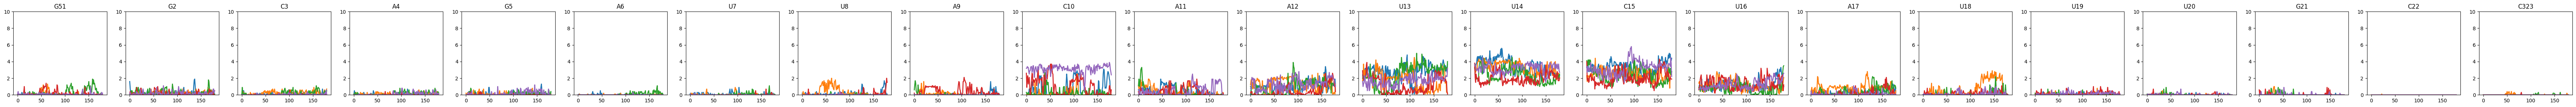

In [2]:
YMAX = 10

fig, ax = plt.subplots(1,23)
fig.set_size_inches(92, 3)

for residue_index_rna in range(0, 23):
    atom_indices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_indices_rna_residue)
    atom_index_rna_residue_max = max(atom_indices_rna_residue)

    for trial in range(len(cmd_interactions)):
        ax[residue_index_rna].plot(cmd_interactions[trial, :, atom_index_rna_residue_min:atom_index_rna_residue_max+1, :].sum(axis=(0, 1)).reshape(-1, 10).mean(axis=1), linewidth=2)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, YMAX)

C10-O2-ARG125-HE 0.026929982046678635 0.31134352373290425
A12-H61-LEU72-O 0.44703770197486536 0.0
U13-H3-THR74-OG1 0.5834829443447038 0.07884151246983105
U13-O2-THR74-H 0.599640933572711 0.08045052292839903
U14-O2-THR118-H 0.9946140035906643 0.9863234111021721
U14-O2'-THR118-HG1 0.5565529622980251 0.5108608205953339
U14-HO2'-THR118-O 0.7289048473967684 0.674979887369268
C15-OP2-ARG120-H 0.6947935368043088 0.5937248592115849
C15-OP2-ALA121-H 0.3877917414721723 0.24537409493161705
C15-H42-ALA117-O 0.3877917414721723 0.39742558326629124
C15-O2-THR34-HG1 0.31597845601436264 0.24617860016090104
U16-OP2-ASN71-HD21 0.4883303411131059 0.2847948511665326


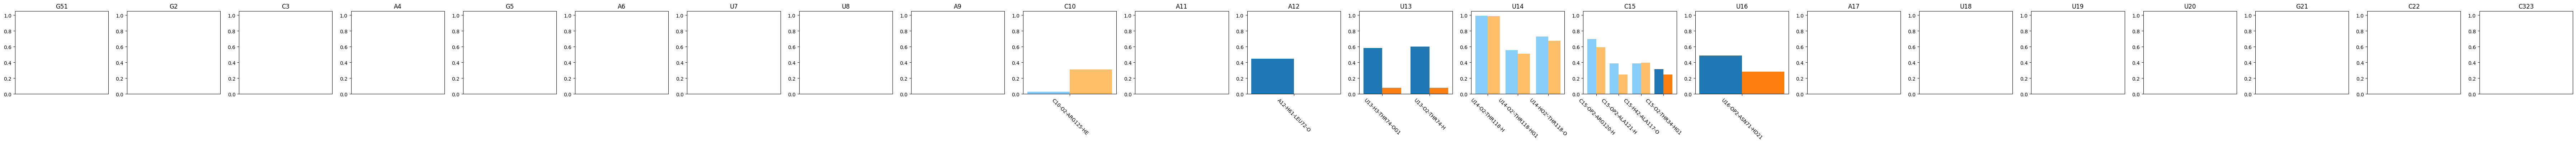

In [3]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

FRACTION_THRESHOLD = 0.3

fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            region = "rrm"
            if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                region = "rgg"
            if fraction_0 > FRACTION_THRESHOLD or fraction_1 > FRACTION_THRESHOLD:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

C10-N3-ARG125-HH11 0.025134649910233394 0.26387771520514886
C10-O2-ARG125-HE 0.026929982046678635 0.31134352373290425
C10-O2-ARG125-HH11 0.01615798922800718 0.17779565567176187
C10-O2'-NME126-H 0.0017953321364452424 0.18101367658889783
A12-OP1-ARG125-HE 0.1059245960502693 0.0008045052292839903
A12-OP1-NME126-H 0.12746858168761221 0.0056315366049879325
A12-H61-LEU72-O 0.44703770197486536 0.0
A12-H62-THR74-OG1 0.20107719928186715 0.0
U13-OP1-THR74-H 0.0 0.168141592920354
U13-OP1-ARG76-HH21 0.17594254937163376 0.004827031375703942
U13-OP2-ARG76-HH12 0.13464991023339318 0.02413515687851971
U13-OP2-ARG76-HH22 0.1992818671454219 0.031375703942075624
U13-O4-ARG76-H 0.02154398563734291 0.2003218020917136
U13-H3-THR74-OG1 0.5834829443447038 0.07884151246983105
U13-H3-THR74-O 0.05385996409335727 0.22928399034593724
U13-O2-THR74-H 0.599640933572711 0.08045052292839903
U13-O2-ARG76-H 0.24236983842010773 0.05551086082059534
U13-O2'-LYS82-HZ1 0.10233393177737882 0.03459372485921158
U13-O2'-LYS82-HZ2

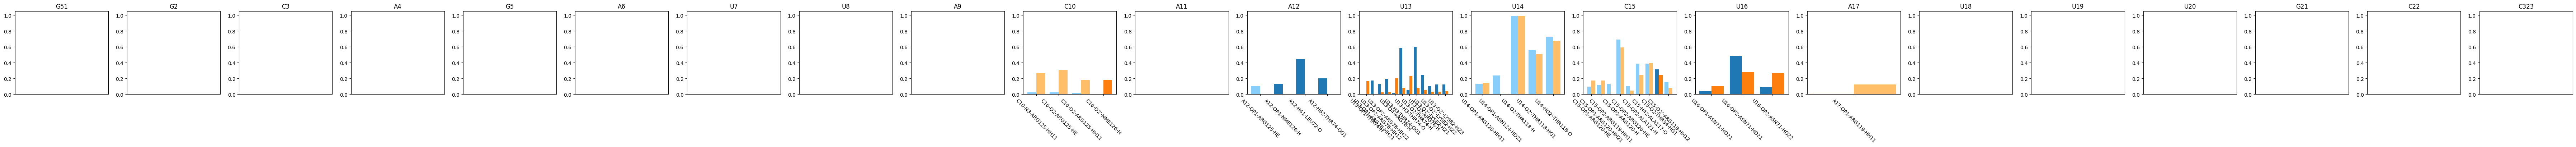

In [4]:
def make_label_protein(atom):
    return f"{atom.residue.name}{atom.residue.index}-{atom.name}"
    return f"{atom.residue.name}{atom.residue.index+252}-{atom.name}"


atom_indices_protein_rgion = {
    "rrm": list(gleap_target.topology.select("resid  24 to 116")),
    "rgg": list(gleap_target.topology.select("resid 117 to 125")),
}

colors = [
    {
        "rrm": "tab:blue",
        "rgg": "lightskyblue",
    },
    {
        "rrm": "tab:orange",
        "rgg": "#FFBE67",
    },
]

FRACTION_THRESHOLD = 0.1

fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

# cmd_interactions_transpose_concat = np.concatenate(cmd_interactions.transpose(0, 3, 1, 2))
cmd_interactions_transpose_concat = np.concatenate(cmd_interactions[:, :, :, ::5].transpose(0, 3, 1, 2))

metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl_all/metastabled_trajs_concat_2.pickle", "rb"))[::50]
for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    atom_index_rna_residue_min = min(atom_idices_rna_residue)
    atom_index_rna_residue_max = max(atom_idices_rna_residue)

    i_bar = 0
    xticks = []
    for atom_index_rna_residue in range(atom_index_rna_residue_min, atom_index_rna_residue_max+1):
        for atom_index_protein in atom_indices_protein:
            fraction_0 = cmd_interactions_transpose_concat[metastabled_trajs_concat==0, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()
            fraction_1 = cmd_interactions_transpose_concat[metastabled_trajs_concat==1, atom_index_protein-atom_index_protein_min, atom_index_rna_residue].mean()

            region = "rrm"
            if atom_index_protein in atom_indices_protein_rgion["rgg"]:
                region = "rgg"
            if fraction_0 > FRACTION_THRESHOLD or fraction_1 > FRACTION_THRESHOLD:
                ax[residue_index_rna].bar(i_bar-0.2, fraction_0, width=0.4, color=colors[0][region])
                ax[residue_index_rna].bar(i_bar+0.2, fraction_1, width=0.4, color=colors[1][region])
                i_bar += 1
                xticks.append(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}")
                print(f"{gleap_target.topology.atom(atom_index_rna_residue)}-{make_label_protein(gleap_target.topology.atom(atom_index_protein))}", fraction_0, fraction_1)

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 1.05)
    ax[residue_index_rna].set_xticks(range(len(xticks)), xticks, rotation=-45)

del cmd_interactions_transpose_concat

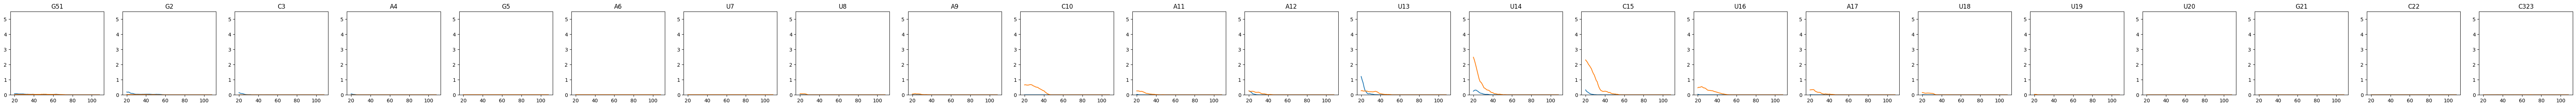

In [5]:
fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

pacs_interactions_trial_mean = pacs_interactions.mean(axis=0)

for residue_index_rna in range(0, 23):
    atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

    pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)

    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
    ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

    ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
    ax[residue_index_rna].set_ylim(0, 5.5)

In [6]:
fig, ax = plt.subplots(len(pacs_interactions), 23)
fig.set_size_inches(92, 3*len(pacs_interactions))

for trial in range(len(pacs_interactions)):
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")

        pacs_interactions_rna_sum = pacs_interactions[trial, :, atom_idices_rna_residue].sum(axis=0)

        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0))
        ax[trial, residue_index_rna].plot(pacs_interactions_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0))

        ax[trial, residue_index_rna].set_title(f"{trial}-{gleap_target.topology.residue(residue_index_rna)}")
        ax[trial, residue_index_rna].set_ylim(0, 5.5)

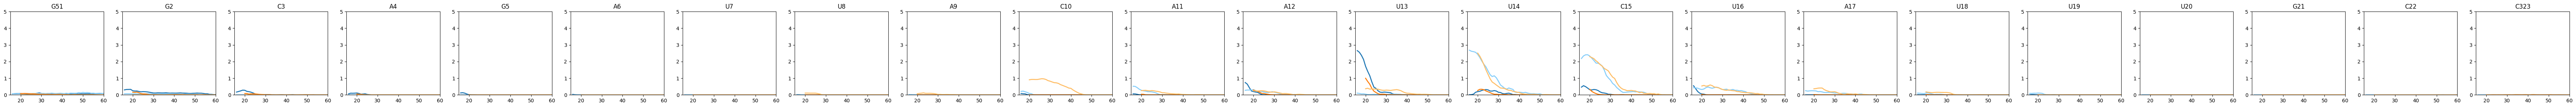

In [7]:
trial_groups_initial = [
    [0, 1, 2, 3, 4, 5, 6, 7, 9, 24, 25, 26, 27, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 5)

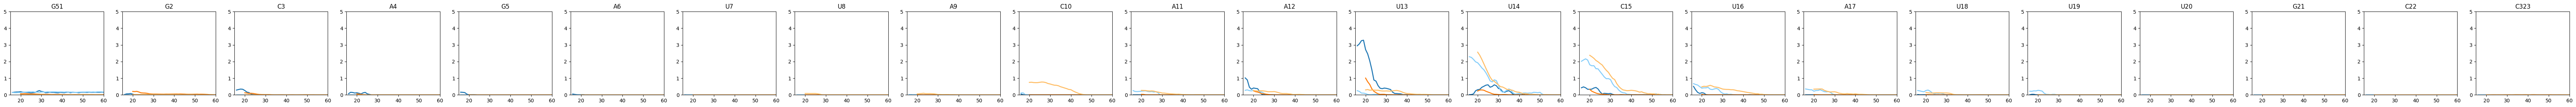

In [8]:
trial_groups_initial = [
    [4, 7, 25, 26, 28, 29],
    [],
]
trial_groups_initial[1] = [trial for trial in range(50) if not trial in trial_groups_initial[0]]


fig, ax = plt.subplots(1, 23)
fig.set_size_inches(92, 3)

for i_trial_group, trial_group_trials in enumerate(trial_groups_initial):
    pacs_interactions_trial_sum = np.zeros((len(atom_indices_protein), len(atom_indices_rna), 120))
    for trial in trial_group_trials:
        pacs_interactions_trial_sum += pacs_interactions[trial]
    pacs_interactions_trial_mean = pacs_interactions_trial_sum / len(trial_group_trials)
    
    for residue_index_rna in range(0, 23):
        atom_idices_rna_residue = gleap_target.topology.select(f"resid {residue_index_rna}")
    
        pacs_interactions_trial_mean_rna_sum = pacs_interactions_trial_mean[:, atom_idices_rna_residue].sum(axis=1)
    
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rrm"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rrm"], linestyle="-", linewidth=2)
        ax[residue_index_rna].plot(pacs_interactions_trial_mean_rna_sum[atom_indices_protein_rgion["rgg"]-atom_index_protein_min].sum(axis=0), c=colors[i_trial_group]["rgg"], linestyle="-", linewidth=2)
    
        ax[residue_index_rna].set_title(gleap_target.topology.residue(residue_index_rna))
        ax[residue_index_rna].set_xlim(15, 60)
        ax[residue_index_rna].set_ylim(0, 5)